# 01. Simulator và kiểm định

Chương này trả lời câu hỏi: **vì sao tin được con số do simulator sinh ra.** Nội dung:

1. Mô hình thị trường: cầu, cung, ghép xe, bỏ chờ và hủy.
2. Đường throughput và wild goose chase (A1).
3. Hiệu chỉnh (CAL).
4. Bốn kiểm thử nghiệm thu còn lại: CRN (A2), dao động của π_θ (A3), tính đơn điệu (A4), thời gian chạy (A5).
5. Các bộ dữ liệu dùng cho phân tích.

Mọi phép tính nằm trong `analysis/` (chủ yếu `analysis/validation.py`, có test ở `tests/test_validation.py`); notebook chỉ gọi hàm và trình bày. Tiêu chí đạt: xem README, mục *Kiểm thử*.

**Dữ liệu cần** (`runs/` không commit; lệnh sinh lại ở README, mục *Tái lập kết quả*; W0 = quy mô Hà Nội, tiền VND, `config_hash` 514d0b41c378):

| Thư mục | Dùng cho |
|---|---|
| `runs/cal_s8/a1_w0_grid25` | A1: `--mode throughput_curve` (lưới 0,25…2,5) |
| `runs/s8/w0/all_off_5seeds_full` | CAL: all_off 5 seed, log đầy đủ (9 chỉ tiêu) |
| `runs/s10/w0/policy_table` | A2 (b): `all_on_B` của bảng chính sách, 30 seed; A3: số lần bật/tắt của các dòng tầng vùng |
| `runs/s10/w0/sweep_ring1_dr` | A2 (b): θ = 0,3 của quét θ, cùng seed |
| `runs/s8/w0/switchback_c7_28d` | A4: hiệu ứng theo tứ phân vị slack |
| `runs/s10/w0/a5_evaluate_1proc` | A5-HN: `--mode evaluate --set runner.n_procs=1`, 3 seed |
| `runs/s8/w0/*`, `runs/s8/w1/*` | các bộ dữ liệu W0 và W1 (26 bộ, mục 5) |


In [1]:
from analysis.notebook import require_runs, setup
from analysis.plots import save_figure

plt = setup()   # repository root, shared plot style, wide pandas display
S8 = ["calibrate_budget", "gte", "gte_bigfleet", "legacy_28d", "legacy_gu_0_28d", "legacy_gu_0p5_28d", "legacy_gu_2_28d",
      "rider_ab_28d", "switchback_c1_28d", "switchback_c7_28d", "switchback_call_28d", "all_on_5seeds_full",
      "all_off_5seeds_full"]
(throughput_dir, cal_full_dir, table_dir, sweep_dir, a5_dir, *dataset_dirs) = require_runs(
    "runs/cal_s8/a1_w0_grid25", "runs/s8/w0/all_off_5seeds_full", "runs/s10/w0/policy_table", "runs/s10/w0/sweep_ring1_dr",
    "runs/s10/w0/a5_evaluate_1proc", *[f"runs/s8/w0/{d}" for d in S8], *[f"runs/s8/w1/{d}" for d in S8])
s8 = dict(zip(S8, dataset_dirs[:len(S8)]))


In [2]:
import dataclasses

import pandas as pd
from IPython.display import Markdown, display

from analysis import figures, evaluation, validation
from analysis.estimate import effect_by_bin, experiment_frame, sign_changes
from analysis.plots import throughput_figure
from analysis.qini_vs_value import policy_runs
from sim.config import config_hash, load_config
from sim.population import build_world, describe_world
from sim.rng import Rng

cfg = load_config("config/default.yaml")
print("config_hash(default.yaml) =", config_hash(cfg))

config_hash(default.yaml) = 514d0b41c378


## 1. Mô hình thị trường

Simulator là mô hình tác tử, thời gian rời rạc (tick 60 giây, slot 15 phút) trên lưới ô lục giác dạng torus. Mỗi tick chạy 10 bước theo thứ tự cố định. Các thành phần chính:

- **Cầu (M2).** Mỗi ô sinh session theo Poisson với cường độ `base_sessions_per_cell_h × demand_scale × w_z × hour_profile[h]`. Session là **lượt mở app**, không phải request: rider thấy giá và ETA báo, rồi quyết định đặt theo logit (M4). Voucher làm tăng xác suất đặt; ETA dài làm giảm.
- **Cung (M8, M9).** Đội xe cố định đi theo lịch ca. **Cung độc lập với chính sách:** tài xế không phản ứng với voucher. Xe rảnh lâu thì điều chuyển sang ô kề theo trọng số tĩnh. Vị trí xe vẫn đổi theo chính sách, vì nó là hệ quả của các chuyến đã chạy; đó là kênh tranh chấp cung cần đo.
- **Ghép xe (M5).** Kiểu *first dispatch*: mỗi đơn lấy ngay xe rảnh gần nhất, mở rộng theo vành tới `max_pickup_eta_min` = 30 phút. Đây là giao thức sinh ra wild goose chase (WGC) khi xe rảnh thưa: xe ở xa được gửi đi đón, mất thời gian đi đón, nên càng ít xe rảnh hơn.
- **Bỏ chờ và hủy (M7).** Đơn chưa ghép được thì rider bỏ sau `max_wait` (lognormal, mode 5 phút). Khi xe đang đi đón, rider hủy theo hazard tăng tuyến tính với ETA đón vượt 3 phút.

Bảng dưới là thế giới tĩnh của `default.yaml` (sinh một lần theo `world_seed`).

In [3]:
world = build_world(cfg, Rng.from_config(cfg))
print(describe_world(cfg, world))

cells            61 (radius 4, torus True, area 5.17 km2 each)
cell weight      min 0.26  max 2.66  (mean 1)
travel time      mean between cells 30.6 min  (fastest hour 21.9, slowest hour 41.8); farthest ring 55.7 min at the slowest hour
riders           120000  per home cell: min 504  max 5133
sessions         149,805 expected per day
fleet            1150 drivers, shift_mode schedule
hour               0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17  18  19  20  21  22  23
on shift         403 350 307 249 200 155 357 523 597 584 627 662 708 755 741 768 772 749 702 611 527 496 471 449


Cầu có hai đỉnh (8h và 18h). Sau khi hiệu chỉnh lịch ca (dồn ca vào 5–7,5h), số xe trong ca lúc 7–8h bằng ≈ 0,75 giờ đỉnh thay vì 0,45 như thế giới cũ, nên vùng căng cung không còn dồn vào 5–8h; voucher gây hại ở 8h và 17–19h (notebook 04). Phần căng của W1 đến thêm từ mưa và sự kiện.


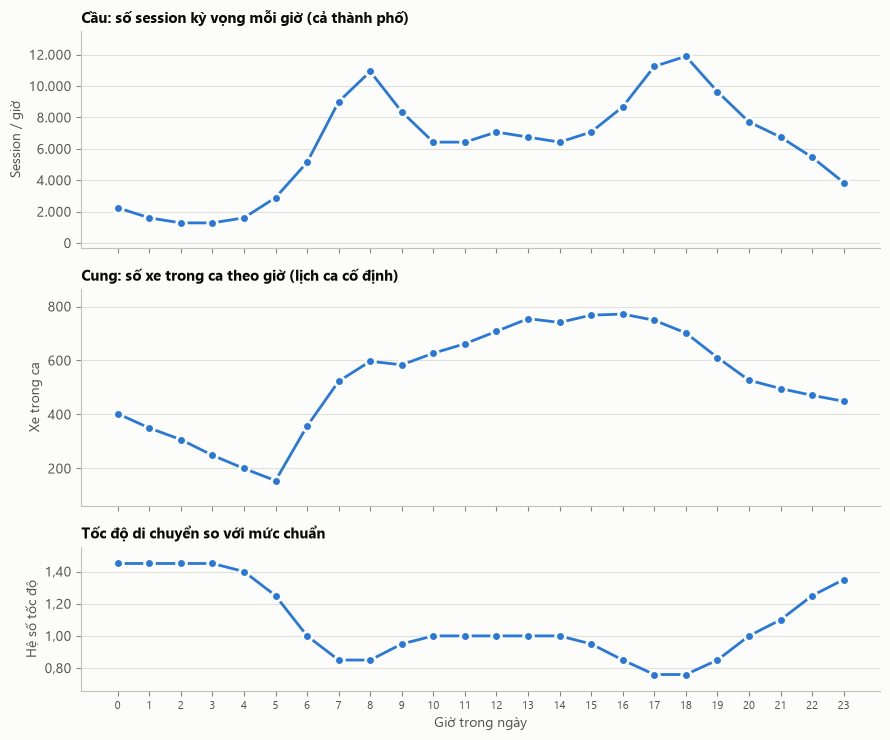

In [4]:
market = validation.market_by_hour(cfg)
fig = figures.market_figure(market)
save_figure(fig, "01_thi_truong_theo_gio")
plt.show()

## 2. Đường throughput và wild goose chase (A1)

A1 là kiểm thử quan trọng nhất: simulator phải **tự sinh ra** đoạn throughput giảm khi cầu vượt cung, chứ không được cài sẵn. Cách chạy: mọi xe online suốt lượt, cầu và tốc độ hằng số tại giờ tham chiếu 18, quét `demand_scale` trên lưới **0,25…2,5** (10 mức; Hà Nội bão hòa từ 2,25 nên lưới 0,25…4,0 của thành phố cũ chỉ đo nhiễu trên đoạn phẳng), 3 seed.


In [5]:
throughput = pd.read_parquet(throughput_dir / "results" / "throughput_curve.parquet")
summary = validation.throughput_summary(throughput)
display(summary.round(3))
display(validation.a1_checks(summary))

,demand_scale,completed_per_h,mean_slack,mean_pickup_eta_min
0,0.25,514.958,16.438,2.526
1,0.50,1019.194,6.854,2.681
2,0.75,1478.458,3.442,3.059
3,1.00,1829.764,1.613,3.883
4,1.25,2005.125,0.664,5.300
5,1.50,2020.028,0.266,7.123
6,1.75,1930.250,0.118,9.454
7,2.00,1789.181,0.068,12.248
8,2.25,1630.125,0.053,14.863
9,2.50,1622.639,0.053,14.993


,criterion,measure,passed
0,1. tăng rồi đạt đỉnh,"đỉnh 2.020,0 chuyến/giờ ở demand_scale 1,50",True
1,"2. mức cầu lớn nhất ≤ 0,95 × đỉnh","0,803 × đỉnh",True
2,"3. slack < 0,45 ở đoạn giảm","slack lớn nhất sau đỉnh 0,118",True
3,"4. ETA đón tăng đơn điệu, bước ≤ 3 phút","bước lớn nhất 2,794 phút",True


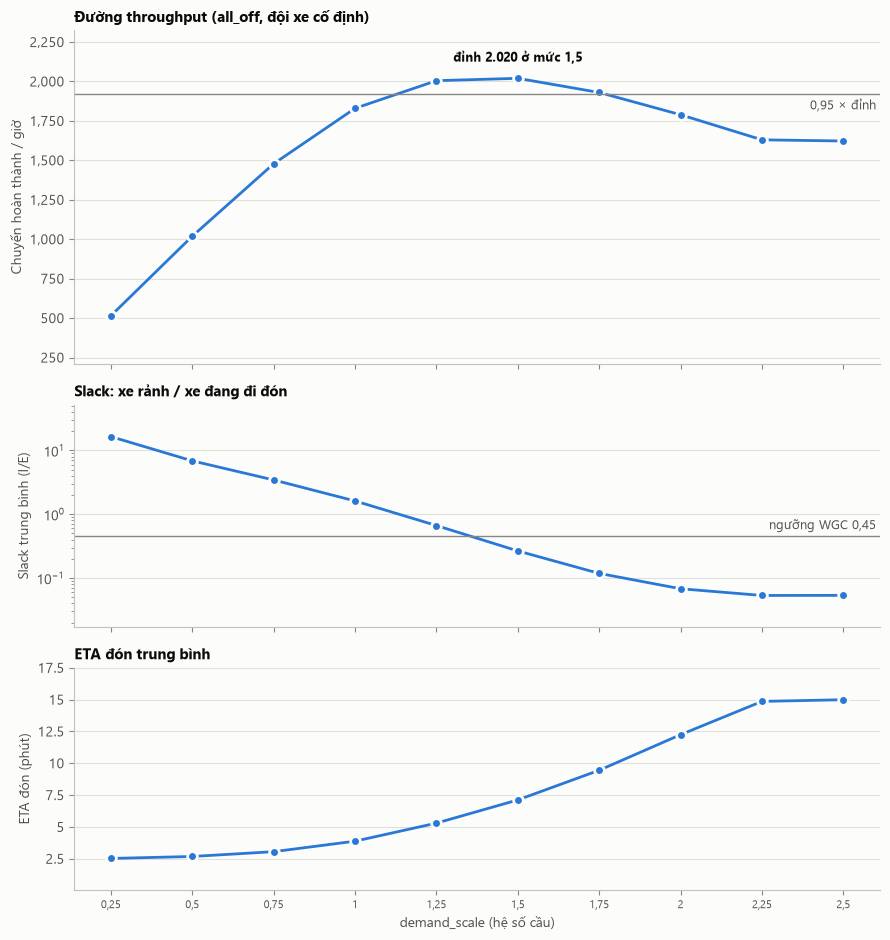

In [6]:
fig = throughput_figure(throughput)
save_figure(fig, "01_throughput")
plt.show()

**Đọc kết quả.** Đạt cả 4 điều kiện trên lưới 0,25…2,5: đỉnh 2.020 chuyến/giờ ở `demand_scale` 1,5; mức 2,5 còn 0,80 × đỉnh; ở đoạn giảm slack ≤ 0,12; ETA đón tăng đơn điệu 2,5 → 15,0 phút, bước lớn nhất 2,8 phút. Qua đỉnh, thêm cầu làm **giảm** số chuyến hoàn thành: xe được gửi đi đón ở xa, thời gian đi đón tăng, rider hủy trong lúc chờ — wild goose chase tự xuất hiện.


## 3. Hiệu chỉnh (CAL)

Chín chỉ tiêu của `calibration_targets` trên all_off, 5 seed (dải đạt ở README, mục *Kiểm thử*; gồm cả `busy_rel_h6/h7/h8`, `mean_trip_km`, `trips_per_driver_day`). Một session ở "ô dư cung" khi slack của **slot trước** cùng ô lớn hơn 1 (slot trước là thứ chính sách nhìn thấy). Giá trị sau hiệu chỉnh W0 (11 vòng).


In [7]:
cal_dirs = validation.full_run_dirs(cal_full_dir, "all_off")
cal = validation.calibration_metrics(cal_dirs)
display(validation.calibration_table(cal, dataclasses.asdict(cfg.calibration_targets)).round(4))


,target,value,lo,hi,in_range
0,p_request_no_voucher,0.1448,0.13,0.17,True
1,request_uplift_surplus,0.5074,0.35,0.70,True
2,share_cellslots_slack_below_0_35,0.1189,0.10,0.35,True
3,share_cellslots_slack_above_1,0.7328,0.30,0.80,True
4,busy_rel_h6,0.4348,0.31,0.61,True
5,busy_rel_h7,0.7622,0.55,0.85,True
6,busy_rel_h8,0.7671,0.63,0.93,True
7,mean_trip_km,5.5558,5.00,8.00,True
8,trips_per_driver_day,16.8139,8.00,18.00,True


Cả 9 chỉ tiêu nằm trong khoảng (P(đặt) 0,145; tăng request +51%; (ô, slot) căng 11,9%, dư 73,3%; xe bận 6/7/8h 0,43 / 0,76 / 0,77; 5,56 km; 16,8 chuyến/xe/ngày). `tests/test_validation.py` kiểm rằng các số này, tính từ bảng đã lưu, bằng đúng số mà test chậm `test_cal_every_target_is_in_range` tính trong bộ nhớ trên cùng seed.


## 4. Các kiểm thử nghiệm thu còn lại

### A2. Số ngẫu nhiên chung (CRN)

- (a) Cùng chính sách, cùng seed chạy hai lần cho N, V giống hệt; (c) hai chính sách khác nhau gặp cùng tập session (cùng `session_id`, `rider_id`, ô đích, `u_book`). Hai ý này là test nhanh (`tests/test_acceptance.py::test_a2a_same_seed_same_run`, `test_a2c_policies_face_the_same_sessions`), pass trong `pytest -q`.
- (b) Với CRN, phương sai của hiệu N(all_on có B) − N(π_θ θ = 0,3) phải ≤ 0,5 × phương sai khi hai chính sách dùng seed độc lập. Dưới đây tính trên 30 seed của bảng chính sách và quét θ; phương sai khi độc lập là Var(N₁) + Var(N₂).

In [8]:
on_b = policy_runs(table_dir).query("label == 'all_on_B'").set_index("seed")["N_completed"]
sweep = pd.read_parquet(sweep_dir / "results" / "policy_results.parquet")
theta_03 = sweep[sweep["theta"] == 0.3].set_index("seed")["N_completed"]
pd.DataFrame([validation.crn_variance_ratio(on_b, theta_03),
              validation.crn_variance_ratio(on_b[on_b.index < 20], theta_03[theta_03.index < 20])],
             index=["30 seed", "20 seed (như tests.md)"]).round(3)


,n_seeds,mean_diff,var_crn,var_indep,ratio
30 seed,30,-1294.933,5616.823,17991.908,0.312
20 seed (như tests.md),20,-1308.250,4998.092,20606.018,0.243


Tỷ lệ 0,31 (30 seed) và 0,24 (20 seed), dưới ngưỡng 0,5: CRN giảm phương sai của hiệu giữa hai chính sách 3–4 lần (thế giới cũ 6–7 lần; quy mô Hà Nội có nhiều ngẫu nhiên trong ghép xe hơn). Đây là lý do mọi so sánh chính sách trong notebook 02 đều ghép cặp theo seed.

### A3. Dao động của π_θ

Số lần bật/tắt mỗi ô mỗi ngày của các dòng tầng vùng trong bảng chính sách (30 seed; `analysis.evaluation.switch_table`).


In [9]:
switches = evaluation.switch_table(policy_runs(table_dir))
switches[switches["switches_mean"] > 0][["label", "theta", "switches_mean", "switches_median", "switches_p90", "share_cells_off"]].round(2)


,label,theta,switches_mean,switches_median,switches_p90,share_cells_off
13,pi_hourB_ring1_dr_kvnd,2.3,23.71,23.81,24.63,0.51
14,pi_hourB_city_dr_kvnd,1.6,13.40,14.00,16.00,0.35


Trung vị 23,8 lần/ô/ngày với `ring1` θ̂_B = 2,3 (tắt 51% (ô, slot)) và 14,0 với `city` θ̂_B = 1,6 — cao hơn mức 12 của tiêu chí A3. Hysteresis h = 0,1 chưa đo lại trên thế giới mới (thế giới cũ: giảm nhẹ, không đổi N). Dao động không làm hỏng đánh giá (N vẫn ghép cặp được) nhưng là ràng buộc vận hành: notebook 02 đề xuất giữ trạng thái tối thiểu 180 phút (≤ 8 lần/ngày) hoặc dùng `city`.


In [10]:
frame = experiment_frame(s8["switchback_c7_28d"])
a4 = effect_by_bin(frame, "cell_lag", quantiles=4)
display(a4.round(4))
print("số lần đổi dấu:", sign_changes(a4["effect"]))


,bin,n_off,n_on,rate_off,rate_on,effect,ci_lo,ci_hi,share_on
0,"[0, 0.2)",240353,542404,0.0931,0.1297,0.0365,0.0339,0.0391,0.6929
1,"[0.2, 0.818182)",384346,404258,0.1056,0.1593,0.0538,0.0511,0.0569,0.5126
2,"[0.818182, 3.22222)",430811,356077,0.1266,0.1917,0.0651,0.0626,0.0677,0.4525
3,"[3.22222, inf)",526183,260492,0.1462,0.2138,0.0676,0.0655,0.0697,0.3311


số lần đổi dấu: 0


Không đổi dấu: hiệu ứng dương và tăng dần theo slack (+3,7 → +6,8 chuyến / 100 session). Cột `share_on` lệch khỏi 50% ở nhóm căng nhất (0,69) cho thấy `slack_lag_slot` đã bị chính nhánh bật/tắt của khối tác động (biến điều tiết không cân bằng) — lý do notebook 04 (mục 4) đo độ căng **trước** khối.


In [11]:
r = pd.read_parquet(a5_dir / "results" / "policy_results.parquet")
pd.DataFrame([{**validation.per_seed_summary(r, "runtime_s"), "limit_s": cfg.performance.max_seconds_per_sim_day}]).round(2)


,median,min,max,n,limit_s
0,18.04,16.83,18.52,3,60.0


## 5. Các bộ dữ liệu dùng cho phân tích

- **W0** (`runs/s8/w0`): luật cũ 28 ngày với 4 mức nhắm theo `u_latent` (`legacy_28d`, `legacy_gu_*`), A/B theo rider, switchback cụm 1 / 7 / toàn thành phố, GTE 10 seed, GTE đội xe rất lớn (6.000 xe), bật/tắt toàn bộ 5 seed log đầy đủ, pilot ngân sách.
- **W1** (`runs/s8/w1`): cùng 13 bộ với biến động tự nhiên (mưa, sự kiện, cầu theo ngày, tài xế nghỉ; `config/world_w1.yaml`).


In [12]:
datasets = validation.datasets_table(dataset_dirs)
cols = ["name", "mode", "policy", "design", "n_runs", "seeds", "days", "budget_B_vnd", "N_mean", "spent_mean",
        "size_mb", "config_hash", "problems"]
datasets[[c for c in cols if c in datasets.columns]].round(1)

,name,mode,policy,design,n_runs,seeds,days,budget_B_vnd,N_mean,spent_mean,size_mb,config_hash,problems
0,calibrate_budget,calibrate_budget,all_on,,1,9000,1.0,113760488.4,NaN,NaN,0.0,ad3c146cbfa1,
1,gte,gte,all_off/all_on,,20,0–9,1.0,NaN,21303.4,1.898796e+08,0.0,ad3c146cbfa1,
2,gte_bigfleet,gte,all_off/all_on,,20,0–9,1.0,NaN,31366.6,3.084702e+08,0.0,ad4d4627d39c,
3,legacy_28d,generate,legacy,,1,0,28.0,113760488.4,588644.0,3.185180e+09,304.9,62605caf8130,
4,legacy_gu_0_28d,generate,legacy,,1,0,28.0,113760488.4,582590.0,2.734933e+09,304.8,872fac608c3b,
5,legacy_gu_0p5_28d,generate,legacy,,1,0,28.0,113760488.4,587123.0,3.029481e+09,304.9,a31b6e59532e,
6,legacy_gu_2_28d,generate,legacy,,1,0,28.0,113760488.4,588299.0,3.185174e+09,304.7,70bc6ba2f9bf,
7,rider_ab_28d,generate,experiment,"rider_ab, p_on 0.5, block 60 phút",1,0,28.0,NaN,612331.0,6.058699e+09,295.4,f7947c059f8e,
8,switchback_c1_28d,generate,experiment,"cluster_switchback, cụm 1, p_on 0.5, block 60 ...",1,0,28.0,NaN,608525.0,5.818406e+09,298.1,eef351b8d1e4,
9,switchback_c7_28d,generate,experiment,"cluster_switchback, cụm 7, p_on 0.5, block 60 ...",1,0,28.0,NaN,605994.0,5.683522e+09,296.5,1fa408c7ff88,


## Tóm tắt

| Kiểm thử | Kết quả | Ghi chú |
|---|---|---|
| A1 throughput | đạt 4/4 (lưới 0,25…2,5) | đỉnh ở `demand_scale` 1,5; đoạn giảm có slack ≤ 0,12, WGC tự xuất hiện |
| A2 CRN | (a), (c) đạt (test nhanh); (b) tỷ lệ phương sai 0,31 | ngưỡng 0,5 |
| A3 dao động | 14–24 lần/ô/ngày ở các dòng tầng vùng | ràng buộc vận hành; kiểm thử chỉ để báo cáo |
| A4 đơn điệu | 0 lần đổi dấu | moderator bị treatment tác động → notebook 04 đo trước khối |
| A5-HN | ≤ 60 giây/ngày (18,2 s `all_on`, 1 tiến trình) | 3 seed, `--mode evaluate` |
| CAL | 9/9 (5 seed) | sau hiệu chỉnh W0 |

Tất cả số trong bảng đọc từ `runs/` qua `analysis/validation.py`; cùng seed, test chậm cho cùng số.
